# Машинное обучение, ФКН ВШЭ

## Практическое задание 8. Метод опорных векторов и аппроксимация ядер

### Общая информация

Дата выдачи: 02.02.2024

Мягкий дедлайн: 23:59MSK 19.02.2024

Жесткий дедлайн: 23:59MSK 25.02.2024

### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимальная оценка за работу (без учёта бонусов) — 10 баллов.

Сдавать задание после указанного жёсткого срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

### Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:
* Ноутбук homework-practice-08-random-features-Username.ipynb

Username — ваша фамилия и имя на латинице именно в таком порядке

### О задании

На занятиях мы подробно обсуждали метод опорных векторов (SVM). В базовой версии в нём нет чего-то особенного — мы всего лишь используем специальную функцию потерь, которая не требует устремлять отступы к бесконечности; ей достаточно, чтобы отступы были не меньше +1. Затем мы узнали, что SVM можно переписать в двойственном виде, который, позволяет заменить скалярные произведения объектов на ядра. Это будет соответствовать построению модели в новом пространстве более высокой размерности, координаты которого представляют собой нелинейные модификации исходных признаков.

Ядровой SVM, к сожалению, довольно затратен по памяти (нужно хранить матрицу Грама размера $d \times d$) и по времени (нужно решать задачу условной оптимизации с квадратичной функцией, а это не очень быстро). Мы обсуждали, что есть способы посчитать новые признаки $\tilde \varphi(x)$ на основе исходных так, что скалярные произведения этих новых $\langle \tilde \varphi(x), \tilde \varphi(z) \rangle$ приближают ядро $K(x, z)$.

Мы будем исследовать аппроксимации методом Random Fourier Features (RFF, также в литературе встречается название Random Kitchen Sinks) для гауссовых ядер. Будем использовать формулы, которые немного отличаются от того, что было на лекциях (мы добавим сдвиги внутрь тригонометрических функций и будем использовать только косинусы, потому что с нужным сдвигом косинус превратится в синус):
$$\tilde \varphi(x) = (
\cos (w_1^T x + b_1),
\dots,
\cos (w_n^T x + b_n)
),$$
где $w_j \sim \mathcal{N}(0, 1/\sigma^2)$, $b_j \sim U[-\pi, \pi]$.

На новых признаках $\tilde \varphi(x)$ мы будем строить любую линейную модель.

Можно считать, что это некоторая новая парадигма построения сложных моделей. Можно направленно искать сложные нелинейные закономерности в данных с помощью градиентного бустинга или нейронных сетей, а можно просто нагенерировать большое количество случайных нелинейных признаков и надеяться, что быстрая и простая модель (то есть линейная) сможет показать на них хорошее качество. В этом задании мы изучим, насколько работоспособна такая идея.

### Алгоритм

Вам потребуется реализовать следующий алгоритм:
1. Понизить размерность выборки до new_dim с помощью метода главных компонент.
2. Для полученной выборки оценить гиперпараметр $\sigma^2$ с помощью эвристики (рекомендуем считать медиану не по всем парам объектов, а по случайному подмножеству из где-то миллиона пар объектов): $$\sigma^2 = \text{median}_{i, j = 1, \dots, \ell, i \neq j} \left\{\sum_{k = 1}^{d} (x_{ik} - x_{jk})^2 \right\}$$
3. Сгенерировать n_features наборов весов $w_j$ и сдвигов $b_j$.
4. Сформировать n_features новых признаков по формулам, приведённым выше.
5. Обучить линейную модель (логистическую регрессию или SVM) на новых признаках.
6. Повторить преобразования (PCA, формирование новых признаков) к тестовой выборке и применить модель.

Тестировать алгоритм мы будем на данных Fashion MNIST. Ниже код для их загрузки и подготовки.

In [2]:
import keras
import warnings
from keras.datasets import fashion_mnist

warnings.filterwarnings("ignore")

(x_train_pics, y_train), (x_test_pics, y_test) = fashion_mnist.load_data()
x_train = x_train_pics.reshape(y_train.shape[0], -1)
x_test = x_test_pics.reshape(y_test.shape[0], -1)

__Задание 1. (5 баллов)__

Реализуйте алгоритм, описанный выше. Можете воспользоваться шаблоном класса ниже или написать свой интерфейс.

Ваша реализация должна поддерживать следующие опции:
1. Возможность задавать значения гиперпараметров new_dim (по умолчанию 50) и n_features (по умолчанию 1000).
2. Возможность включать или выключать предварительное понижение размерности с помощью метода главных компонент.
3. Возможность выбирать тип линейной модели (логистическая регрессия или SVM с линейным ядром).

Протестируйте на данных Fashion MNIST, сформированных кодом выше. Если на тесте у вас получилась доля верных ответов не ниже 0.84 с гиперпараметрами по умолчанию, то вы всё сделали правильно.

In [103]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression
import numpy as np
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [ ]:
class RFFPipeline(BaseEstimator, TransformerMixin):
    def __init__(self, n_features=1000, new_dim=50, use_PCA=True, classifier='logreg'):
        """        
        Implements pipeline, which consists of PCA decomposition,
        Random Fourier Features approximation and linear classification model.
        
        n_features, int: amount of synthetic random features generated with RFF approximation.

        new_dim, int: PCA output size.
        
        use_PCA, bool: whether to include PCA preprocessing.
        
        classifier, string: either 'svm' or 'logreg', a linear classification model to use on top of pipeline.
        
        Feel free to edit this template for your preferences.    
        """
        self.n_features = n_features
        self.use_PCA = use_PCA
        self.new_dim = new_dim
        self.classifier = classifier
        self.pca = None
        if self.new_dim is not None:
            self.pca = PCA(n_components = self.new_dim)
        self.w = None
        self.b = None
        self.clf = None
        self.sigma = None
        
    def fit(self, X, y):
        """
        Fit all parts of algorithm (PCA, RFF, Classification) to training set.
        """

        # Your code here: (￣▽￣)/♫•*¨*•.¸¸♪

        XX = X.copy()
        if self.use_PCA:
            XX = self.pca.fit_transform(XX)
        k = np.random.randint(0, XX.shape[0], size=(int(1e6), 2))
        vals = np.sum( (XX[k[:, 0]] - XX[k[:, 1]]) ** 2, axis = 1)
        sigma2 = np.median(vals)
        self.sigma = sigma2
        

        self.w = np.random.normal(loc=0, scale=1, size=(self.n_features, XX.shape[1]))
        #correct: self.w = np.random.normal(loc=0, scale=1 / self.sigma, size=(self.n_features, XX.shape[1]))

        self.b = np.random.uniform(-np.pi, np.pi, size=(self.n_features))

        res = XX @ self.w.T + self.b
        c = np.sqrt(2.0 / self.sigma)
        res = np.cos(res * c)
        #correct: res = np.sqrt(2.0 / self.n_features) * np.cos(res)

        if self.classifier == "logreg":
            self.clf = LogisticRegression()
        else:
            self.clf = SVC(kernel='linear', probability=True)
        
        self.clf.fit(res, y)

        return self

    def predict_proba(self, X):
        """
        Apply pipeline to obtain scores for input data.
        """
        # Your code here: (￣▽￣)/♫•*¨*•.¸¸♪

        XX = X.copy()
        if self.use_PCA:
            XX = self.pca.transform(XX)
        res = XX @ self.w.T + self.b
        c = np.sqrt(2.0 / self.sigma)
        res = np.cos(res * c)

        return self.clf.predict_proba(res)
        
    def predict(self, X):
        """
        Apply pipeline to obtain discrete predictions for input data.
        """
        #Your code here: (￣▽￣)/♫•*¨*•.¸¸♪


        XX = X.copy()
        if self.use_PCA:
            XX = self.pca.transform(XX)
        res = XX @ self.w.T + self.b
        res = np.cos(res * np.sqrt(2.0 / self.sigma))

        return self.clf.predict(res)


In [5]:
# Your code here: (￣▽￣)/♫•*¨*•.¸¸♪
cur_model = RFFPipeline()

cur_model.fit(x_train, y_train)

preds = cur_model.predict(x_test)
print(f"Accuracy score: {accuracy_score(y_test, preds)}")

Accuracy score: 0.8636


__Задание 2. (3 балла)__

Сравните подход со случайными признаками с обучением SVM на исходных признаках. Попробуйте вариант с обычным (линейным) SVM и с ядровым SVM. Ядровой SVM может очень долго обучаться, поэтому можно делать любые разумные вещи для ускорения: брать подмножество объектов из обучающей выборки, например.

Сравните подход со случайными признаками с вариантом, в котором вы понижаете размерность с помощью PCA и обучаете градиентный бустинг. Используйте одну из реализаций CatBoost/LightGBM/XGBoost, не забудьте подобрать число деревьев и длину шага.

Сделайте выводы — насколько идея со случайными признаками работает? Сравните как с точки зрения качества, так и с точки зрения скорости обучения и применения.

In [54]:
# Your code here: (￣▽￣)/♫•*¨*•.¸¸♪
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
import time

x_train_smol, y_train_smol = x_train[:10000], y_train[:10000]

models = [SVC(kernel='linear'), SVC(kernel='rbf')]
model_names = ["linear", "rbf"]

for model in enumerate(models):
    start_time = time.time_ns()
    cur_model = model[1]
    pipeline = Pipeline([
        ('grid_search', GridSearchCV(estimator=cur_model, param_grid={}, scoring='accuracy', cv=5, n_jobs=-1))
    ])
    pipeline.fit(x_train_smol, y_train_smol)
    grid_search = pipeline.named_steps['grid_search']
    end_time = time.time_ns()

    print(f"Accuracy ({model_names[model[0]]}): {grid_search.best_score_:.4f}")
    print(f"Training time: {(end_time - start_time) / 1e9} s")



Accuracy (linear): 0.8019
Training time: 31.7560207 s
Accuracy (rbf): 0.8588
Training time: 38.8423166 s


In [56]:
import xgboost as xgb

params = {
    'objective': 'multi:softmax',
    'eval_metric': 'merror',
    'seed': 42,
    'num_class': 10
}

x_train_smol = x_train.copy()
y_train_smol = y_train.copy()

pca = PCA(n_components = 0.95)
x_train_smol_scaled = pca.fit_transform(x_train_smol)
x_test_scaled = pca.transform(x_test)

dtrain = xgb.DMatrix(x_train_smol_scaled, label=y_train_smol)
dtest = xgb.DMatrix(x_test_scaled, label=y_test)

num_boost_round = 100
watchlist = [(dtrain, 'train'), (dtest, 'test')]

xgb_model = xgb.XGBClassifier(
    params,
    dtrain,
    num_boost_round=100,
    max_depth=10
)
grid_search = GridSearchCV(
    estimator=xgb_model,
    cv = 5,
    scoring='accuracy',
    param_grid={}
)

pipeline.fit(x_train_smol_scaled, y_train_smol)
grid_search = pipeline.named_steps['grid_search']
print(f"Accuracy (boosting): {grid_search.best_score_:.4f}")

Accuracy (boosting): 0.8938


Случайные признаки работают отлично. Они гораздо быстрее чем обычное rbf ядро и могут масштабировать приближение через n_features. Случайные признаки также обеспечивают сопоставимое бустингу качество при этом встроенный метод должен работать немного быстрее

__Задание 3. (2 балла)__

Проведите эксперименты:
1. Помогает ли предварительное понижение размерности с помощью PCA? 
2. Как зависит итоговое качество от n_features? Выходит ли оно на плато при росте n_features?
3. Важно ли, какую модель обучать — логистическую регрессию или SVM?

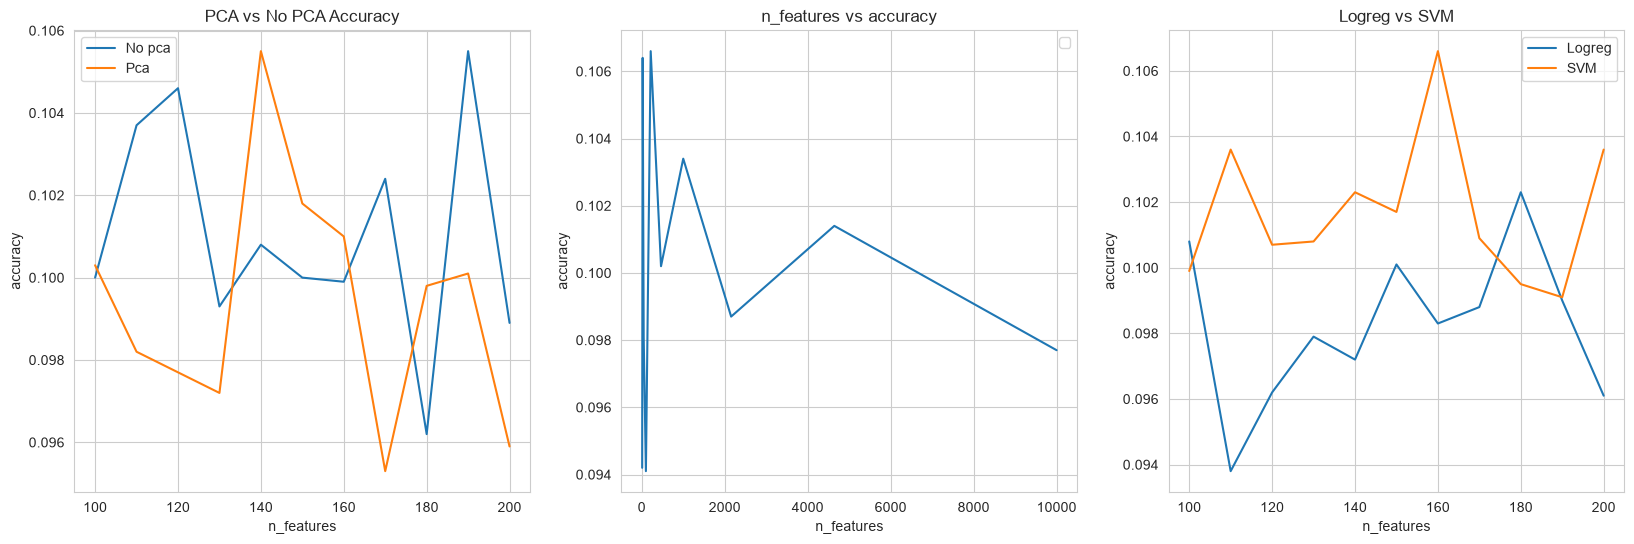

In [106]:
# Your code here: (￣▽￣)/♫•*¨*•.¸¸♪

#I'm a lazy bum, accept it

x_train_smol = x_train[:2000]
y_train_smol = y_train[:2000]

fig, ax = plt.subplots(1, 3, figsize=(20, 6))
n_features = np.arange(100, 201, 10)

scores = []
for i in n_features:
    model = RFFPipeline(use_PCA=False, n_features=i)
    model.fit(x_train_smol, y_train_smol)
    model_pca = RFFPipeline(use_PCA=False, n_features=i)
    model_pca.fit(x_train_smol, y_train_smol)

    preds = model.predict(x_test)
    score1 = accuracy_score(y_test, preds)
    preds = model_pca.predict(x_test)
    score2 = accuracy_score(y_test, preds)
    scores.append( (score1, score2) )

k = np.array(scores)
a, b = k.T
ax[0].plot(n_features, a, label="No pca")
ax[0].plot(n_features, b, label="Pca")
ax[0].set_title("PCA vs No PCA Accuracy")
ax[0].set_xlabel("n_features")
ax[0].set_ylabel("accuracy")
ax[0].legend()

n_features = np.arange(100, 201, 10)

ls = np.logspace(1, 4, 10)

scores = []
for i in ls:
    model = RFFPipeline(use_PCA=False, n_features=int(i))
    model.fit(x_train_smol, y_train_smol)
    preds = model.predict(x_test)
    score = accuracy_score(y_test, preds)
    scores.append(score)

ax[1].plot(ls, scores)
ax[1].set_title("n_features vs accuracy")
ax[1].set_xlabel("n_features")
ax[1].set_ylabel("accuracy")
ax[1].legend()

scores = []
for i in n_features:
    model = RFFPipeline(use_PCA=False, n_features=i, classifier="logreg")
    model.fit(x_train_smol, y_train_smol)
    model_pca = RFFPipeline(use_PCA=False, n_features=i, classifier="svm")
    model_pca.fit(x_train_smol, y_train_smol)

    preds = model.predict(x_test)
    score1 = accuracy_score(y_test, preds)
    preds = model_pca.predict(x_test)
    score2 = accuracy_score(y_test, preds)
    scores.append( (score1, score2) )

k = np.array(scores)
a, b = k.T
ax[2].plot(n_features, a, label="Logreg")
ax[2].plot(n_features, b, label="SVM")
ax[2].set_title("Logreg vs SVM")
ax[2].set_xlabel("n_features")
ax[2].set_ylabel("accuracy")
ax[2].legend()


1. PCA не добавляет значительной разницы, так как может заглушать не только шум но и нелинейные связи

2. Так как мы строим приближение ядра, то в какой-то момент качество должно выйти на плато где качество модели не будет сильно меняться

3. Так как обе модели строят разделяющие гиперплоскости существенной разницы в качестве нет.

### Бонус

__Задание 4. (Максимум 2 балла)__

Как вы, должно быть, помните с курса МО-1, многие алгоритмы машинного обучения работают лучше, если признаки данных некоррелированы. Оказывается, что для RFF существует модификация, позволяющая получать ортогональные случайные признаки (Orthogonal Random Features, ORF). Об этом методе можно прочитать в [статье](https://proceedings.neurips.cc/paper/2016/file/53adaf494dc89ef7196d73636eb2451b-Paper.pdf). Реализуйте класс для вычисления ORF по аналогии с основным заданием. Обратите внимание, что ваш класс должен уметь работать со случаем n_features > new_dim (в статье есть замечание на этот счет). Проведите эксперименты, сравнивающие RFF и ORF, сделайте выводы.

In [ ]:
# Your code here: (￣▽￣)/♫•*¨*•.¸¸♪

__Задание 5. (Максимум 1 балл)__

Поэкспериментируйте с функциями для вычисления новых случайных признаков. Не обязательно использовать косинус от скалярного произведения — можно брать знак от него, хэш и т.д. Придумайте побольше вариантов для генерации признаков и проверьте, не получается ли с их помощью добиваться более высокого качества. Также можете попробовать другой классификатор поверх случайных признаков, сравните результаты.

In [ ]:
# Your code here: (￣▽￣)/♫•*¨*•.¸¸♪

__Задание 6. (Максимум 1 балл)__

Реализуйте класс ядровой Ridge регрессии (Лекция 13, $\S 1.2$), для оптимизации используте градиентный спуск, а не аналитическую формулу. Также подумайте о том, как в формулах правильно учесть свободный коэффициент. Затем адаптируйте вашу реализацию RFF под задачу регрессии. Сравните вашу ядровую регрессию и RFF на синтетических данных.

Функция потерь: 
$$
Q(w) = \frac{1}{2} ||\Phi \Phi^T w - y||^2 + \frac{\lambda}{2} w^T \Phi \Phi^T w \rightarrow \min_w,
$$
где $\Phi \Phi^T = K$, $K = (k(x_i, x_j))_{i, j = 1}^{\ell}$.

Предсказание: 
$
y(x) = k(x)^T w,
$
где $k(x)$ — вектор функций ядра от пар объектов $(x, x_i)_{i=1}^{\ell}$.

Вы можете изменять представленный ниже шаблон по своему усмотрению.

In [ ]:
import numpy as np
from sklearn.base import RegressorMixin
from sklearn.gaussian_process.kernels import RBF

class KernelRidgeRegression(RegressorMixin):
    """
    Kernel Ridge regression class
    """

    def __init__(self,         
        lr=0.01,
        regularization=1.,
        tolerance=1e-2,
        max_iter=1000,
        batch_size=64,
        kernel_scale=1.
    ):
        """
        :param lr: learning rate
        :param regularization: regularization coefficient
        :param tolerance: stopping criterion for square of euclidean norm of weight difference
        :param max_iter: stopping criterion for iterations
        :param batch_size: size of the batches used in gradient descent steps
        :parame kernel_scale: length scale in RBF kernel formula
        """

        self.lr: float = lr
        self.regularization: float = regularization
        self.w: np.ndarray | None = None

        self.tolerance: float = tolerance
        self.max_iter: int = max_iter
        self.batch_size: int = batch_size
        self.loss_history: list[float] = []
        self.kernel = RBF(kernel_scale)

    def calc_loss(self, x: np.ndarray, y: np.ndarray) -> float:
        """
        Calculating loss for x and y dataset
        :param x: features array
        :param y: targets array
        """
        raise NotImplementedError

    def calc_grad(self, x: np.ndarray, y: np.ndarray) -> float:
        """
        Calculating gradient for x and y dataset
        :param x: features array
        :param y: targets array
        """
        raise NotImplementedError

    def fit(self, x: np.ndarray, y: np.ndarray) -> "KernelRidgeRegression":
        """
        Fitting weights for x and y dataset
        :param x: features array
        :param y: targets array
        :return: self
        """
        raise NotImplementedError

    def predict(self, x: np.ndarray) -> np.ndarray:
        """
        Predicting targets for x dataset
        :param x: features array
        :return: prediction: np.ndarray
        """
        raise NotImplementedError